#### 1. EDA Disease Data

In [1]:
import pandas, numpy, matplotlib
disease_path = './disease-muenceberg/disease-muencheberg.xlsx'
disease_muencheberg = pandas.read_excel(disease_path)
disease_muencheberg_sp = disease_muencheberg[disease_muencheberg['disease_de'] =='Septoria-Arten']

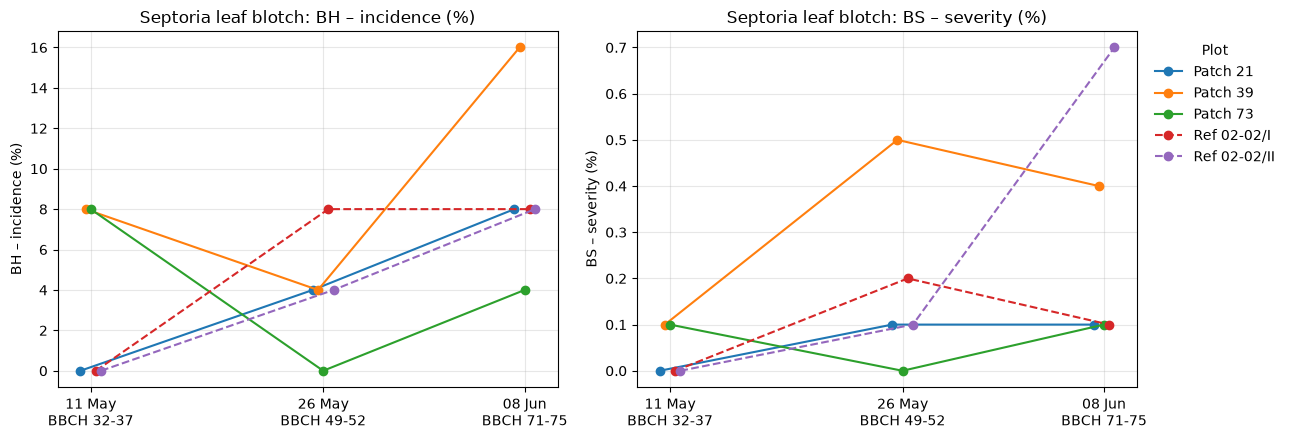

In [2]:
import matplotlib.pyplot as plt

sp = disease_muencheberg_sp.copy()
sp['date'] = pandas.to_datetime(sp['date'])
sp = sp.sort_values('date')

# x-axis labels: date + BBCH stage
bbch = sp.drop_duplicates('date').set_index('date')['bbch_range']
plots = sorted(sp['plot_id'].unique())
# small horizontal offset per plot so identical values don't hide each other
offsets = {p: pandas.Timedelta(hours=8 * (i - (len(plots) - 1) / 2)) for i, p in enumerate(plots)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, col, title in [(axes[0], 'bh_pct', 'BH – incidence (%)'),
                       (axes[1], 'bs_pct', 'BS – severity (%)')]:
    for plot_id, g in sp.groupby('plot_id'):
        ls = '--' if plot_id.startswith('Ref') else '-'
        ax.plot(g['date'] + offsets[plot_id], g[col], marker='o', ls=ls, label=plot_id)
    ax.set_title(f'Septoria leaf blotch: {title}')
    ax.set_ylabel(title)
    ax.set_xticks(bbch.index)
    ax.set_xticklabels([f"{d:%d %b}\nBBCH {b}" for d, b in bbch.items()])
    ax.grid(alpha=0.3)
axes[1].legend(title='Plot', frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1))
fig.tight_layout()
plt.show()

#### 2. EDA Weather Data

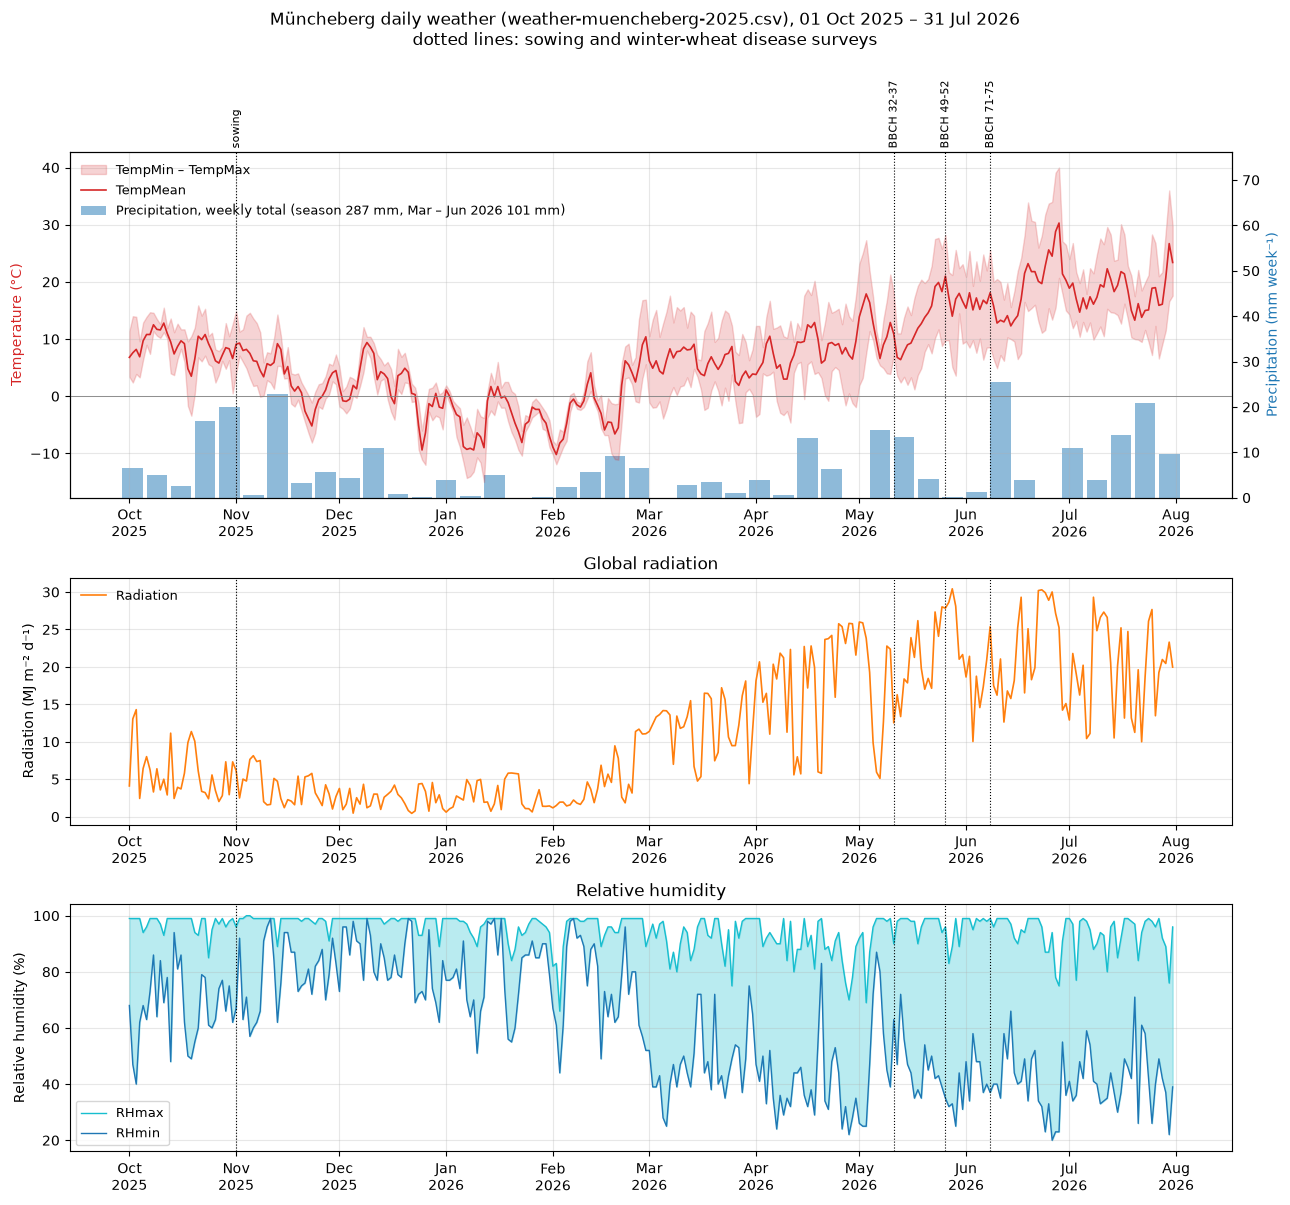

In [3]:
import matplotlib.dates as mdates

weather = pandas.read_csv('./weather-muenceberg/weather-muencheberg-2025.csv')
weather['Date'] = pandas.to_datetime(weather['Date'], format='%d/%m/%Y')
weather = weather.set_index('Date')

# crop calendar: sowing (management csv) and the winter-wheat survey dates with BBCH (disease data)
sowing_doy = int(pandas.read_csv('./management-muenceberg/management-muencheberg.csv')['sowingDOY'].iloc[0])
sowing_date = pandas.Timestamp(weather.index[0].year, 1, 1) + pandas.Timedelta(days=sowing_doy - 1)
crop_events = {sowing_date: 'sowing'}
crop_events.update({d: f'BBCH {b}' for d, b in sp.drop_duplicates('date').set_index('date')['bbch_range'].items()})

rain_week = weather['Precipitation'].resample('W').sum()   # weeks ending on Sunday
spring = weather.loc['2026-03-01':'2026-06-30', 'Precipitation'].sum()

fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True, gridspec_kw={'height_ratios': [1.4, 1, 1]})

# (1) temperature and weekly rain
ax = axes[0]
ax_rain = ax.twinx()
ax_rain.bar(rain_week.index - pandas.Timedelta(days=3), rain_week, width=6, color='tab:blue', alpha=0.5,
            label=f'Precipitation, weekly total (season {weather["Precipitation"].sum():.0f} mm, '
                  f'Mar – Jun 2026 {spring:.0f} mm)')
ax_rain.set_ylim(0, 3 * rain_week.max())   # keep the bars in the lower third
ax_rain.set_ylabel('Precipitation (mm week⁻¹)', color='tab:blue')
ax.fill_between(weather.index, weather['TempMin'], weather['TempMax'], color='tab:red', alpha=0.2, label='TempMin – TempMax')
ax.plot(weather.index, weather['TempMean'], color='tab:red', lw=1.2, label='TempMean')
ax.axhline(0, color='grey', lw=0.6)
ax.set_ylabel('Temperature (°C)', color='tab:red')
ax.set_zorder(ax_rain.get_zorder() + 1)   # temperature drawn over the rain bars
ax.patch.set_visible(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax_rain.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', frameon=False, fontsize=9)

# (2) radiation
ax = axes[1]
ax.plot(weather.index, weather['Radiation'] / 1000, color='tab:orange', lw=1.2, label='Radiation')
ax.set_ylabel('Radiation (MJ m⁻² d⁻¹)')
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.set_title('Global radiation')

# (3) relative humidity
ax = axes[2]
ax.fill_between(weather.index, weather['RHmin'], weather['RHmax'], color='tab:cyan', alpha=0.3)
ax.plot(weather.index, weather['RHmax'], color='tab:cyan', lw=1, label='RHmax')
ax.plot(weather.index, weather['RHmin'], color='tab:blue', lw=1, label='RHmin')
ax.set_ylabel('Relative humidity (%)')
ax.legend(loc='lower left', frameon=True, fontsize=9)
ax.set_title('Relative humidity')

for ax in axes:
    for d, label in crop_events.items():
        ax.axvline(d, color='black', lw=0.8, ls=':')
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(axis='x', labelbottom=True)   # date labels under every panel
for d, label in crop_events.items():
    axes[0].text(d, 1.01, label, transform=axes[0].get_xaxis_transform(), rotation=90,
                 ha='center', va='bottom', fontsize=8)
fig.suptitle('Müncheberg daily weather (weather-muencheberg-2025.csv), 01 Oct 2025 – 31 Jul 2026\n'
             'dotted lines: sowing and winter-wheat disease surveys', y=1.0)
fig.tight_layout()
plt.show()

#### 3. EDA Soil Data

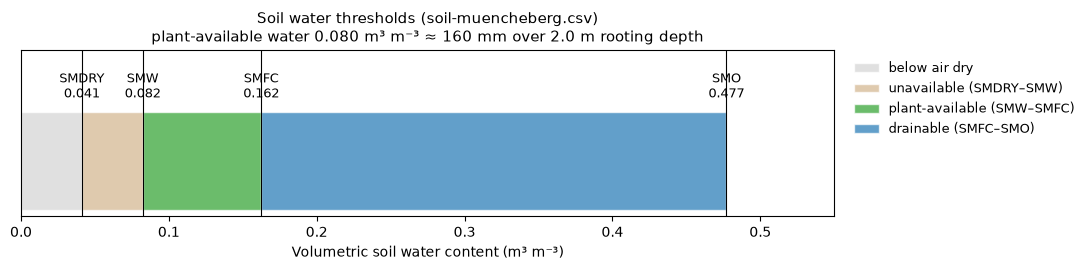

In [4]:
# soil-muencheberg.csv: LINTUL5 soil parameters (SoilGrids texture + Saxton-Rawls 2006, WS1 location)
soil = pandas.read_csv('./soil-muenceberg/soil-muencheberg.csv').set_index('location')
s = soil.loc[2025]
# display(soil.T.rename(columns={2025: 'value'}))

# soil water content thresholds (m3 m-3)
levels = [('SMDRY', s['SMDRY']), ('SMW', s['SMW']), ('SMFC', s['SMFC']), ('SMO', s['SMO'])]
paw_mm = (s['SMFC'] - s['SMW']) * s['RDMSO'] * 1000  # plant-available water in root zone

fig, ax = plt.subplots(figsize=(11, 2.8))
segments = [(0, s['SMDRY'], 'lightgrey', 'below air dry'),
            (s['SMDRY'], s['SMW'], 'tan', 'unavailable (SMDRY–SMW)'),
            (s['SMW'], s['SMFC'], 'tab:green', 'plant-available (SMW–SMFC)'),
            (s['SMFC'], s['SMO'], 'tab:blue', 'drainable (SMFC–SMO)')]
for lo, hi, color, label in segments:
    ax.barh(0, hi - lo, left=lo, color=color, alpha=0.7, edgecolor='white', label=label)
for name, v in levels:
    ax.axvline(v, color='black', lw=0.8)
    ax.text(v, 0.48, f'{name}\n{v:.3f}', ha='center', va='bottom', fontsize=9)
ax.set_xlim(0, 0.55)
ax.set_ylim(-0.45, 0.9)
ax.set_yticks([])
ax.set_xlabel('Volumetric soil water content (m³ m⁻³)')
ax.set_title(f'Soil water thresholds (soil-muencheberg.csv)\n'
             f'plant-available water {s["SMFC"] - s["SMW"]:.3f} m³ m⁻³ ≈ {paw_mm:.0f} mm '
             f'over {s["RDMSO"]:.1f} m rooting depth', fontsize=11)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

#### 4. Torchcrop potential production

The crop model (torchcrop, LINTUL5) simulates the 2025/26 winter wheat under
**potential production**: enough water and nitrogen all season, so only the
weather and the crop stages limit growth. Three steps:

1. **4.1 Inputs**: weather, soil, site and crop settings.
2. **4.2 Crop stages**: fit the model's emergence, anthesis and maturity to the observed dates.
3. **4.3 Run**: the final run and its plot.

##### 4.1 Inputs

| Input | Source |
|---|---|
| Weather | `weather-muencheberg-2025.csv` (station WS1, daily, 1 Oct 2025 – 31 Jul 2026) |
| Sowing | `management-muencheberg.csv`: 1 Nov 2025 |
| Site | `site-muencheberg.csv`: location of WS1, altitude 77 m, CO₂ 427 ppm (2025 average) |
| Soil | `soil-muencheberg.csv` (does not limit growth here, because of automatic irrigation) |
| Crop | torchcrop `wheat` preset, made a winter wheat: it now also responds to day length and winter cold (values from WOFOST `wheat.yaml`) |

In [5]:
import copy
import torch
from torchcrop import CropParameters, Lintul5Model, SiteParameters, SoilParameters, WeatherDriver

# --- Input files ---
w = weather   # daily weather from section 2
site = pandas.read_csv('./site-muenceberg/site-muencheberg.csv').set_index('location').loc[2025]
management = pandas.read_csv('./management-muenceberg/management-muencheberg.csv').iloc[0]
soil_row = pandas.read_csv('./soil-muenceberg/soil-muencheberg.csv').set_index('location').loc[2025]


In [6]:
# --- Weather: one row per day, columns in the order torchcrop expects ---
assert (w.index.to_series().diff().dropna() == pandas.Timedelta(days=1)).all(), 'weather has missing days'
weather_table = numpy.column_stack([
    w.index.dayofyear, w['TempMean'], w['TempMin'], w['TempMax'],
    w['Radiation'] / 1000,   # kJ -> MJ m-2 d-1
    w['Precipitation'], w['VapPressure'], w['Windspeed']])
weather_drv = WeatherDriver(torch.as_tensor(weather_table, dtype=torch.float32)[None])
weather_drv

WeatherDriver(data=tensor([[[2.7400e+02, 6.8000e+00, 3.4000e+00,  ..., 0.0000e+00,
          8.9000e-01, 1.3000e+00],
         [2.7500e+02, 7.6000e+00, 2.4000e+00,  ..., 2.0000e-01,
          8.6000e-01, 1.6000e+00],
         [2.7600e+02, 8.2000e+00, 3.9000e+00,  ..., 0.0000e+00,
          8.5000e-01, 1.1000e+00],
         ...,
         [2.1000e+02, 2.0700e+01, 1.1500e+01,  ..., 0.0000e+00,
          1.5400e+00, 1.6000e+00],
         [2.1100e+02, 2.6700e+01, 1.6600e+01,  ..., 0.0000e+00,
          1.7300e+00, 1.4000e+00],
         [2.1200e+02, 2.3400e+01, 1.7600e+01,  ..., 5.6000e+00,
          2.0200e+00, 1.3000e+00]]]))

In [7]:
# --- Soil: soil file column -> torchcrop name ---
SOIL_MAP = {'SMDRY': 'wcad', 'SMW': 'wcwp', 'SMFC': 'wcfc', 'SMO': 'wcst', 'CRAIRC': 'crairc', 'SMI': 'wci',
            'SMLOWI': 'wci_lower', 'RDMSO': 'rdmso', 'RUNFR': 'runfr', 'CFEV': 'cfev', 'KSUB': 'ksub',
            'NMINS': 'nmini', 'PMINS': 'pmini', 'KMINS': 'kmini', 'RTNMINS': 'rtnmins', 'RTPMINS': 'rtpmins',
            'RTKMINS': 'rtkmins'}

soil_params = SoilParameters(**{name: torch.tensor([float(soil_row[col])]) for col, name in SOIL_MAP.items()})
soil_params.irri = torch.tensor(1.0)   # automatic irrigation: no water shortage
soil_params

SoilParameters(wcad=tensor([0.0412]), wcwp=tensor([0.0823]), wcfc=tensor([0.1625]), wcst=tensor([0.4771]), wci=tensor([0.1625]), wci_lower=tensor([0.1625]), crairc=tensor([0.0700]), ksub=tensor([1772.4000]), runfr=tensor([0.]), cfev=tensor([2.]), rdmso=tensor([2.]), irri=tensor(1.), irrtab=None, scale_factor_irr=tensor(1.), rtnmins=tensor([0.0250]), rtpmins=tensor([0.0250]), rtkmins=tensor([0.0250]), nmini=tensor([3.]), pmini=tensor([3.]), kmini=tensor([3.]), nminti=tensor(0.), pminti=tensor(0.), kminti=tensor(0.))

In [8]:
# --- Site ---
site_params = SiteParameters(latitude=torch.tensor([site['LATITUDE']]),
                             altitude=torch.tensor([site['ALTITUDE']]),
                             co2=torch.tensor([site['CO2']]),
                             idpl=torch.tensor([float(management['sowingDOY'])]))   # sowing day
site_params

SiteParameters(latitude=tensor([52.4476], dtype=torch.float64), altitude=tensor([77.], dtype=torch.float64), co2=tensor([427.3500], dtype=torch.float64), fpenmtb=tensor([[4.0000e+01, 1.0500e+00],
        [3.6000e+02, 1.0000e+00],
        [7.2000e+02, 9.5000e-01],
        [1.0000e+03, 9.2000e-01],
        [2.0000e+03, 9.2000e-01]]), plant_at_sowing=tensor(1.), idpl=tensor([305.]), idem=tensor(0.))

In [9]:
# --- Crop: torchcrop wheat preset, made a winter wheat (values from WOFOST wheat.yaml) ---
crop_params = CropParameters(crop_name='wheat')
crop_params.iopt = torch.tensor(1.0)     # potential production: no water or nitrogen limit
crop_params.idsl = torch.tensor(2.0)     # development depends on temperature, day length and winter cold
crop_params.phottb = torch.tensor([(0.0, 0.0), (8.0, 0.0), (14.0, 1.0), (24.0, 1.0)])   # day length: no effect below 8 h, full above 14 h
crop_params.vernrt = torch.tensor([(-8.0, 0.0), (-4.0, 0.0), (3.0, 1.0), (10.0, 1.0), (17.0, 0.0), (20.0, 0.0)])   # cold days counted per day, by temperature
crop_params.vbase = torch.tensor(14.0)   # cold days before development starts
crop_params.versat = torch.tensor(70.0)  # cold days that fully meet the cold need
default_params = copy.deepcopy(crop_params)   # keeps the default TSUM values for comparison

In [10]:

def run_cropModel(params):
    """Run torchcrop over the whole weather period."""
    with torch.no_grad():
        model = Lintul5Model(params, soil_params, site_params).eval()
        return model(weather_drv, start_doy=int(w.index[0].dayofyear),
                     fertilizer=torch.zeros(1, weather_drv.n_days, 3))


def stage_dates(run, params):
    """Simulated emergence, anthesis and maturity dates."""
    # states[d] = start of day d, states[d + 1] = end of day d
    tsump_morning = numpy.array([float(x.tsump[0]) for x in run.states[:-1]])
    dvs_evening = run.dvs[0, 1:].numpy()

    def first(mask):
        return w.index[mask.argmax()].date() if mask.any() else None

    return {'emergence': first(tsump_morning >= float(params.tsumem)),   # emergence day: warmth since sowing reaches TSUMEM
            'anthesis': first(dvs_evening >= 1),
            'maturity': first(dvs_evening >= 2)}

##### 4.2 Crop stages (phenology)

The model moves through the crop stages by adding up daily warmth (thermal
time, °C d). Three thresholds set when it reaches emergence, anthesis
(flowering) and maturity. They are fitted to the dates in
`phenology-muencheberg.csv`:

| Parameter | Meaning | Observed info | torchcrop default | Fitted to | Value applied |
|---|---|---|---|---|---|
| `TSUMEM` | thermal time sowing → emergence | emergence 20 Nov 2025 (site diary) | 60 °C d → emergence 10 Nov 2025 | emergence 20 Nov 2025 | 110 °C d → emergence 20 Nov 2025 |
| `TSUM1` | effective thermal time emergence → anthesis | heading (BBCH 49–52) 26 May 2026 (disease survey); anthesis not observed | 1050 °C d → anthesis 17 Jun 2026 | anthesis = heading + 70 °C d = 31 May 2026 | 806 °C d → anthesis 31 May 2026 |
| `TSUM2` | thermal time anthesis → physiological maturity | harvest 21 Jul 2026 (site diary); maturity not observed | 1000 °C d → maturity not reached by 31 Jul | maturity = harvest − 7 d = 14 Jul 2026 | 813 °C d → maturity 14 Jul 2026 |

Default dates: all three thresholds at their defaults.

- **Emergence.** 110 °C d is the warmth added up from sowing to the morning of
  20 Nov. 17–19 Nov were cold (1–2 °C d per day), so any value from 106 to
  110 gives emergence between 17 and 20 Nov.
- **Anthesis.** Not observed. Assumed 70 °C d (about 5 days) after heading.
  This is an assumption, not a value measured for Müncheberg or Germany. The
  survey only tells us it was between 27 May (after BBCH 49–52) and 7 Jun
  (before BBCH 71–75).
- **Maturity.** Not observed. Assumed 7 days before harvest. This is also an
  assumption, not a value measured here. It may be off by a few days.

How the code fits them: it first runs the model with anthesis and maturity
out of reach (the "probe" run). From that run it reads the warmth collected up
to each target date and uses it as the threshold.

In [11]:
# --- 1. Target dates ---
pheno_obs = pandas.read_csv('./phenology-muenceberg/phenology-muencheberg.csv', parse_dates=['date'])
obs = pheno_obs.set_index('event')['date']
EMERGENCE_OBS, HEADING_OBS, HARVEST_OBS = obs['emergence'], obs['heading'], obs['harvest']

HEADING_TO_ANTHESIS = 70.0                          # °C d from heading to anthesis (assumption)
HARVEST_AFTER_MATURITY = pandas.Timedelta(days=7)   # days from maturity to harvest (assumption)

warmth_after_heading = w['TempMean'].clip(lower=0)[w.index > HEADING_OBS].cumsum()
ANTHESIS_EST = warmth_after_heading.index[numpy.argmax(warmth_after_heading >= HEADING_TO_ANTHESIS)]
MATURITY_EST = HARVEST_OBS - HARVEST_AFTER_MATURITY

# --- 2. Probe run: TSUM1 and TSUM2 set out of reach, so the warmth totals can be read on any day ---
day = w.index.get_loc
probe_params = copy.deepcopy(crop_params)
probe_params.tsum1 = torch.tensor(1e4)
probe_params.tsum2 = torch.tensor(1e5)

# TSUMEM: warmth from sowing to the morning of the observed emergence day
probe = run_cropModel(probe_params)
crop_params.tsumem = torch.tensor(float(probe.states[day(EMERGENCE_OBS)].tsump[0]), dtype=torch.float64)

# Run the probe again with the fitted emergence
probe_params.tsumem = crop_params.tsumem
probe = run_cropModel(probe_params)

# TSUM1: warmth from emergence to the end of the anthesis day.
# In the probe, DVS x 10 000 (its TSUM1) is the warmth collected so far.
crop_params.tsum1 = torch.tensor(float(probe.dvs[0, day(ANTHESIS_EST) + 1]) * 1e4, dtype=torch.float64)

# TSUM2: warmth from the end of the anthesis day to the end of the maturity day.
# 0.01 is taken off so rounding does not move maturity one day later.
def tsum_evening(date):
    return float(probe.states[day(date) + 1].tsum[0])

crop_params.tsum2 = torch.tensor(tsum_evening(MATURITY_EST) - tsum_evening(ANTHESIS_EST) - 0.01,
                                 dtype=torch.float64)

# --- 3. Compare default and fitted ---
default_dates = stage_dates(run_cropModel(default_params), default_params)
fitted_dates = stage_dates(run_cropModel(crop_params), crop_params)
phenology_table = pandas.DataFrame({
    'target date': [EMERGENCE_OBS.date(), ANTHESIS_EST.date(), MATURITY_EST.date()],
    'default (°C d)': [float(default_params.tsumem), float(default_params.tsum1), float(default_params.tsum2)],
    'default date': list(default_dates.values()),
    'fitted (°C d)': [float(crop_params.tsumem), float(crop_params.tsum1), float(crop_params.tsum2)],
    'fitted date': list(fitted_dates.values()),
}, index=['emergence (TSUMEM)', 'anthesis (TSUM1)', 'maturity (TSUM2)'])
display(phenology_table.round(0).fillna('not reached'))

,target date,default (°C d),default date,fitted (°C d),fitted date
emergence (TSUMEM),2025-11-20,60.0,2025-11-10,110.0,2025-11-20
anthesis (TSUM1),2026-05-31,1050.0,2026-06-17,806.0,2026-05-31
maturity (TSUM2),2026-07-14,1000.0,not reached,813.0,2026-07-14


##### 4.3 Run

The final run with the fitted thresholds. The plot shows the development stage
with the observed BBCH dates, the leaf area and the biomass.

In [12]:
G_M2_TO_KG_HA = 10.0   # torchcrop biomass is in g m-2

crop_run = run_cropModel(crop_params)
st = crop_run.states[1:]   # end of each day (also used in section 5)
crop_df = pandas.DataFrame({
    'DVS': crop_run.dvs[0, 1:].numpy(),                       # development stage
    'LAI': crop_run.lai[0, 1:].numpy(),                       # leaf area index
    'AGB': [float(x.wlv[0] + x.wlvd[0] + x.wst[0] + x.wstd[0] + x.wso[0]) * G_M2_TO_KG_HA for x in st],   # above-ground biomass
    'WSO': [float(x.wso[0]) * G_M2_TO_KG_HA for x in st],     # grain
}, index=w.index)

print(f"potential yield {float(crop_run.yield_[0]) * G_M2_TO_KG_HA:.0f} kg/ha (dry matter)")
print(f"above-ground biomass at maturity {crop_df.loc[MATURITY_EST, 'AGB']:.0f} kg/ha")
print(f"max LAI {crop_df['LAI'].max():.2f}")

potential yield 8017 kg/ha (dry matter)
above-ground biomass at maturity 17422 kg/ha
max LAI 5.50


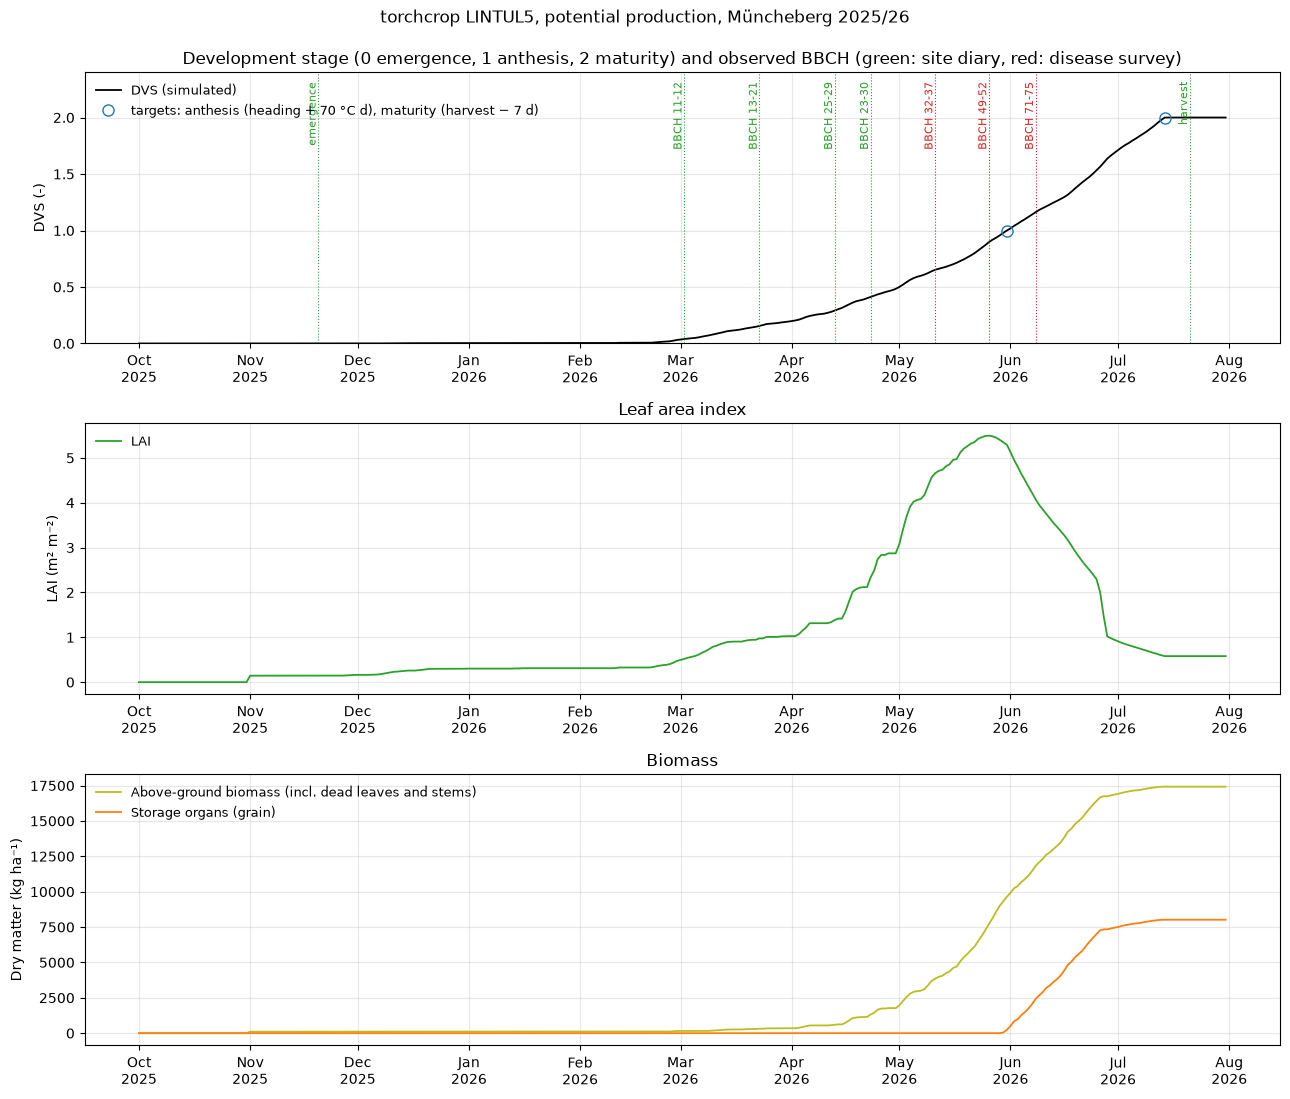

In [13]:
# --- Potential crop trajectory ---
bbch_dates = sp.drop_duplicates('date').set_index('date')['bbch_range']
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

ax = axes[0]
ax.plot(crop_df.index, crop_df['DVS'], color='black', lw=1.3, label='DVS (simulated)')
for d, b in bbch_dates.items():
    ax.axvline(d, color='tab:red', lw=0.8, ls=':')
    ax.text(d, 2.35, f'BBCH {b} ', rotation=90, va='top', ha='right', fontsize=8, color='tab:red')
# site diary: emergence, BBCH stages and harvest
diary = pheno_obs[pheno_obs['event'].isin(['emergence', 'bbch', 'harvest'])]
for d, ev, b in zip(diary['date'], diary['event'], diary['bbch_range']):
    ax.axvline(d, color='tab:green', lw=0.8, ls=':')
    ax.text(d, 2.35, (f'BBCH {b}' if ev == 'bbch' else ev) + ' ', rotation=90, va='top',
            ha='right', fontsize=8, color='tab:green')
# fitted targets: estimated anthesis (DVS 1) and maturity (DVS 2)
ax.plot([ANTHESIS_EST, MATURITY_EST], [1, 2], 'o', mfc='none', mec='tab:blue', ms=8,
        label='targets: anthesis (heading + 70 °C d), maturity (harvest − 7 d)')
ax.set_ylim(0, 2.4)
ax.set_ylabel('DVS (-)')
ax.set_title('Development stage (0 emergence, 1 anthesis, 2 maturity) and observed BBCH (green: site diary, red: disease survey)')

ax = axes[1]
ax.plot(crop_df.index, crop_df['LAI'], color='tab:green', lw=1.3, label='LAI')
ax.set_ylabel('LAI (m² m⁻²)')
ax.set_title('Leaf area index')

ax = axes[2]
ax.plot(crop_df.index, crop_df['AGB'], color='tab:olive', lw=1.3, label='Above-ground biomass (incl. dead leaves and stems)')
ax.plot(crop_df.index, crop_df['WSO'], color='tab:orange', lw=1.3, label='Storage organs (grain)')
ax.set_ylabel('Dry matter (kg ha⁻¹)')
ax.set_title('Biomass')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc='upper left', frameon=False, fontsize=9)
    # own date axis on every panel
    ax.tick_params(labelbottom=True)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
fig.suptitle('torchcrop LINTUL5, potential production, Müncheberg 2025/26', y=0.995)
fig.tight_layout()
plt.show()

#### 5. FraNchEstYN disease model (septoria)

simpest's FraNchEstYN model runs a septoria (leaf blotch) epidemic on top of
the crop from section 4. This first run uses the **standard (canonical)
septoria parameters**. Nothing is fitted, and the disease survey is not used.

| Input | Source |
|---|---|
| Weather | `weather-muencheberg-2025-hourly.csv`: hourly temperature, humidity and rain from station WS1. An hour counts as wet when RH > 90 % or rain ≥ 0.2 mm. |
| Crop | the torchcrop run from section 4 (biomass, grain, light interception, thermal time), sowing to maturity |
| Management | `management-muencheberg.csv`: sowing 1 Nov 2025; no fungicide |
| Disease | `septoria`, canonical parameters |
| Severity output | **upper leaves** (`UpperLeafSeverity`), because the field survey scored only the upper 3–4 leaves. The whole-canopy severity is also kept. |

**Upper leaves.** The model tracks them as a separate pool that opens while
these leaves come out: from the start of stem elongation (BBCH 30, 23 Apr in
the diary) to the flag leaf being fully out (BBCH 39, taken as 14 May: between
BBCH 32–37 on 11 May and BBCH 49–52 on 26 May).

**How an epidemic starts in the model.** Warm, wet hours add up day by day.
Infections can start once this sum reaches `HydroThermalTimeOnset` (10) **and**
the crop is past 25 % of its cycle. Hours colder than 7.5 °C do not count. New
lesions become visible after `LatencyDuration` (19.5 days at the best
temperature, longer when it is cool).

In [14]:
import simpest.models.franchestyn as franchestyn
from simpest.models import fr_diagnostics, fr_inputs

FRANCH_SITE = 'muencheberg'
FRANCH_VARIETY = 'Generic'
FRANCH_DISEASE = 'thisDisease'
SEVERITY_COL = 'UpperLeafSeverity'   # the survey scored the upper 3-4 leaves
SOW_YEAR = int(management['year'])
FRANCH_START_YEAR, FRANCH_END_YEAR = SOW_YEAR, SOW_YEAR + 1   # 2025/26 season

# --- Weather: hourly records from station WS1 ---
weather_hourly = pandas.read_csv('./weather-muenceberg/weather-muencheberg-2025-hourly.csv')
weather_df = fr_inputs.build_weather_df(w.reset_index(), site=FRANCH_SITE, mode='hourly',
                                        weather_hourly=weather_hourly)

# --- Management: sowing day; no fungicide ---
management_df = fr_inputs.build_management_df(
    pandas.read_csv('./management-muenceberg/management-muencheberg.csv'), site=FRANCH_SITE,
    crop='wheat', variety=FRANCH_VARIETY, year_col='year', sowing_doy_col='sowingDOY')

# --- Crop: the torchcrop run from section 4 ---
# The builder expects day 0 = 1 January of the sowing year. Our weather starts 1 Oct,
# so zeros are added in front (only sowing -> maturity is used).
pad = (w.index[0] - pandas.Timestamp(SOW_YEAR, 1, 1)).days


def padded(x):
    return numpy.concatenate([numpy.zeros(pad), numpy.asarray(x, dtype=float)])[None]


tsum_emerged = pandas.Series([float(x.tsum[0]) for x in st], index=w.index)   # thermal time since emergence
crop_model_df = fr_inputs.build_crop_model_df(
    agb=padded(crop_df['AGB']),
    yield_=padded(crop_df['WSO']),
    fint=padded([float(d.frac_intercepted[0]) for d in crop_run.diagnostics]),
    gdd=padded(tsum_emerged),
    dvs=padded(crop_df['DVS']),
    sow_years=[SOW_YEAR],
    sowing_doys=[int(management['sowingDOY'])],
)

# --- Upper leaves: when do they come out? ---
# Start: stem elongation begins (diary, BBCH 23-30). Full: flag leaf fully out (BBCH 39, assumption).
UPPER_LEAVES_START = pheno_obs.loc[pheno_obs['bbch_range'] == '23-30', 'date'].iloc[0]
UPPER_LEAVES_FULL = pandas.Timestamp('2026-05-14')
cycle_pct = 100 * tsum_emerged / tsum_emerged[MATURITY_EST]   # share of the crop cycle completed, as FraNchEstYN counts it

# No observations are used in this run. The model still needs a reference table,
# so it gets one empty placeholder row.
ref_df = pandas.DataFrame([{'sName': FRANCH_SITE, 'variety': FRANCH_VARIETY, 'year': SOW_YEAR + 1, 'DOY': 1,
                            'FINT': None, FRANCH_DISEASE: None}])

# --- Run with the canonical septoria parameters ---
fr_cfg = franchestyn.FranchestynConfig(
    crop_type='wheat',
    disease_type='septoria',
    fungicide_type=None,          # no fungicide
    site=FRANCH_SITE,
    variety=FRANCH_VARIETY,
    disease=FRANCH_DISEASE,
    is_calibration=False,         # nothing is fitted
    use_gdd=True,                 # crop cycle counted in thermal time
    use_prev_day_alignment=True,
    weather_time_step='hourly',
    latitude=float(site['LATITUDE']),
    upper_leaf_pool=True,         # also simulate the upper leaves
    upper_leaf_cycle_start=float(cycle_pct[UPPER_LEAVES_START]),
    upper_leaf_cycle_full=float(cycle_pct[UPPER_LEAVES_FULL]),
)

fr_result = franchestyn.run_franchestyn(
    start_year=FRANCH_START_YEAR, end_year=FRANCH_END_YEAR, config=fr_cfg, weather_df=weather_df,
    management_df=management_df, crop_model_df=crop_model_df, ref_df=ref_df)
fr_sim = fr_diagnostics.simulation_frame(fr_result).set_index('Date')   # severity in %

par = {k: v['value'] for k, v in fr_cfg.disease_parameters.items()}
onset = ((fr_sim['HTtimeSinoculum'] >= par['HydroThermalTimeOnset'])
         & (fr_sim['CycleCompletionPercentage'] >= par['CyclePercentageOnset']))
ONSET = onset.idxmax() if onset.any() else None
end = fr_sim.iloc[-1]
spring = fr_sim.loc[f'{SOW_YEAR + 1}-03-01':f'{SOW_YEAR + 1}-06-30', 'TotalLW']

print(f"simulated season {fr_sim.index[0].date()} – {fr_sim.index[-1].date()}")
print(f"upper leaves come out between {cycle_pct[UPPER_LEAVES_START]:.0f} % and {cycle_pct[UPPER_LEAVES_FULL]:.0f} % of the crop cycle")
print(f"infection onset: {ONSET.date() if ONSET is not None else 'not reached'}"
      + (f" ({fr_sim.loc[ONSET, 'CycleCompletionPercentage']:.0f} % of the crop cycle)" if ONSET is not None else ''))
print(f"days Mar–Jun with >= {par['WetnessDurationMinimum']:.0f} wet hours: {(spring >= par['WetnessDurationMinimum']).sum()} of {len(spring)}")
print(f"max severity: upper leaves {fr_sim[SEVERITY_COL].max():.2f} %, whole canopy {fr_sim['DiseaseSeverity'].max():.2f} %")
print(f"yield attainable {end['YieldAttainable']:.0f} kg/ha, actual {end['YieldActual']:.0f} kg/ha, "
      f"loss {100 * (1 - end['YieldActual'] / end['YieldAttainable']):.1f} %")

simulated season 2025-11-01 – 2026-07-14
upper leaves come out between 28 % and 40 % of the crop cycle
infection onset: 2026-06-22 (75 % of the crop cycle)
days Mar–Jun with >= 10 wet hours: 22 of 122
max severity: upper leaves 0.00 %, whole canopy 0.00 %
yield attainable 8017 kg/ha, actual 8017 kg/ha, loss 0.0 %


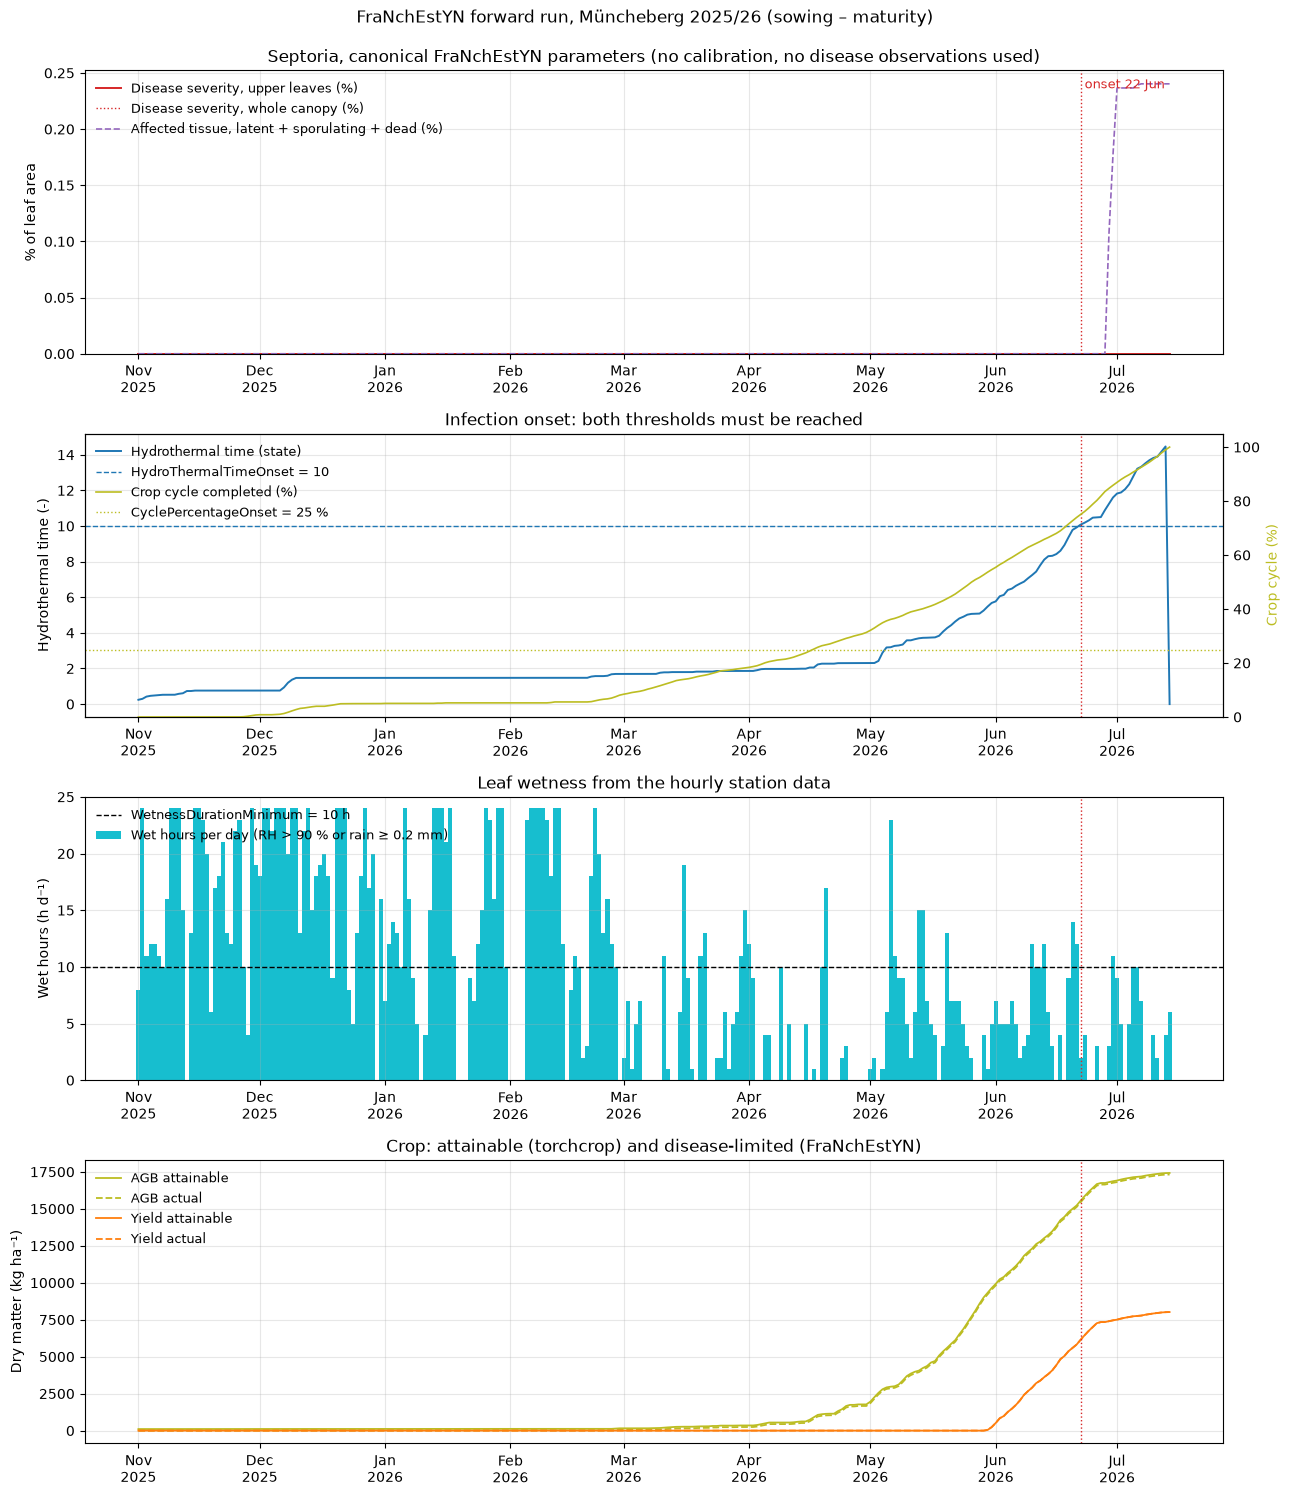

In [15]:
# --- FraNchEstYN results ---
fig, axes = plt.subplots(4, 1, figsize=(13, 15), sharex=True)

# (1) disease
ax = axes[0]
ax.plot(fr_sim.index, fr_sim[SEVERITY_COL], color='tab:red', lw=1.4, label='Disease severity, upper leaves (%)')
ax.plot(fr_sim.index, fr_sim['DiseaseSeverity'], color='tab:red', lw=1.0, ls=':', label='Disease severity, whole canopy (%)')
ax.plot(fr_sim.index, 100 * fr_sim['Affected'], color='tab:purple', lw=1.2, ls='--',
        label='Affected tissue, latent + sporulating + dead (%)')
ax.set_ylabel('% of leaf area')
ax.set_ylim(bottom=0)
ax.set_title('Septoria, canonical FraNchEstYN parameters (no calibration, no disease observations used)')

# (2) onset conditions
ax = axes[1]
ax.plot(fr_sim.index, fr_sim['HTtimeSinoculum'], color='tab:blue', lw=1.4, label='Hydrothermal time (state)')
ax.axhline(par['HydroThermalTimeOnset'], color='tab:blue', ls='--', lw=1,
           label=f"HydroThermalTimeOnset = {par['HydroThermalTimeOnset']:g}")
ax.set_ylabel('Hydrothermal time (-)')
ax2 = ax.twinx()
ax2.plot(fr_sim.index, fr_sim['CycleCompletionPercentage'], color='tab:olive', lw=1.2, label='Crop cycle completed (%)')
ax2.axhline(par['CyclePercentageOnset'], color='tab:olive', ls=':', lw=1,
            label=f"CyclePercentageOnset = {par['CyclePercentageOnset']:g} %")
ax2.set_ylabel('Crop cycle (%)', color='tab:olive')
ax2.set_ylim(0, 105)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left', frameon=False, fontsize=9)
ax.set_title('Infection onset: both thresholds must be reached')

# (3) daily wet hours
ax = axes[2]
ax.bar(fr_sim.index, fr_sim['TotalLW'], width=1, color='tab:cyan', label='Wet hours per day (RH > 90 % or rain ≥ 0.2 mm)')
ax.axhline(par['WetnessDurationMinimum'], color='black', ls='--', lw=1,
           label=f"WetnessDurationMinimum = {par['WetnessDurationMinimum']:g} h")
ax.set_ylabel('Wet hours (h d⁻¹)')
ax.set_ylim(0, 25)
ax.set_title('Leaf wetness from the hourly station data')

# (4) crop: attainable vs actual
ax = axes[3]
ax.plot(fr_sim.index, fr_sim['AGBattainable'], color='tab:olive', lw=1.3, label='AGB attainable')
ax.plot(fr_sim.index, fr_sim['AGBactual'], color='tab:olive', lw=1.3, ls='--', label='AGB actual')
ax.plot(fr_sim.index, fr_sim['YieldAttainable'], color='tab:orange', lw=1.3, label='Yield attainable')
ax.plot(fr_sim.index, fr_sim['YieldActual'], color='tab:orange', lw=1.3, ls='--', label='Yield actual')
ax.set_ylabel('Dry matter (kg ha⁻¹)')
ax.set_title('Crop: attainable (torchcrop) and disease-limited (FraNchEstYN)')

for ax in axes:
    if ONSET is not None:
        ax.axvline(ONSET, color='tab:red', lw=1, ls=':')
    ax.grid(alpha=0.3)
    if ax is not axes[1]:
        ax.legend(loc='upper left', frameon=False, fontsize=9)
    ax.tick_params(labelbottom=True)
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
if ONSET is not None:
    axes[0].text(ONSET, 0.97, f' onset {ONSET:%d %b}', transform=axes[0].get_xaxis_transform(),
                 va='top', fontsize=9, color='tab:red')
fig.suptitle('FraNchEstYN forward run, Müncheberg 2025/26 (sowing – maturity)', y=0.995)
fig.tight_layout()
plt.show()

##### 5.1 Validation against Patch 39

The run above was not fitted to anything, so comparing it with the survey is a
fair test of the model.

**Observations:** septoria severity in winter wheat, Patch 39 (% leaf area on
the upper 3–4 leaves), on three survey dates.

,BBCH,observed (%),simulated (%)
2026-05-11,32-37,0.1,0.0
2026-05-26,49-52,0.5,0.0
2026-06-08,71-75,0.4,0.0


RMSE, simulation vs Patch 39: 0.37 %


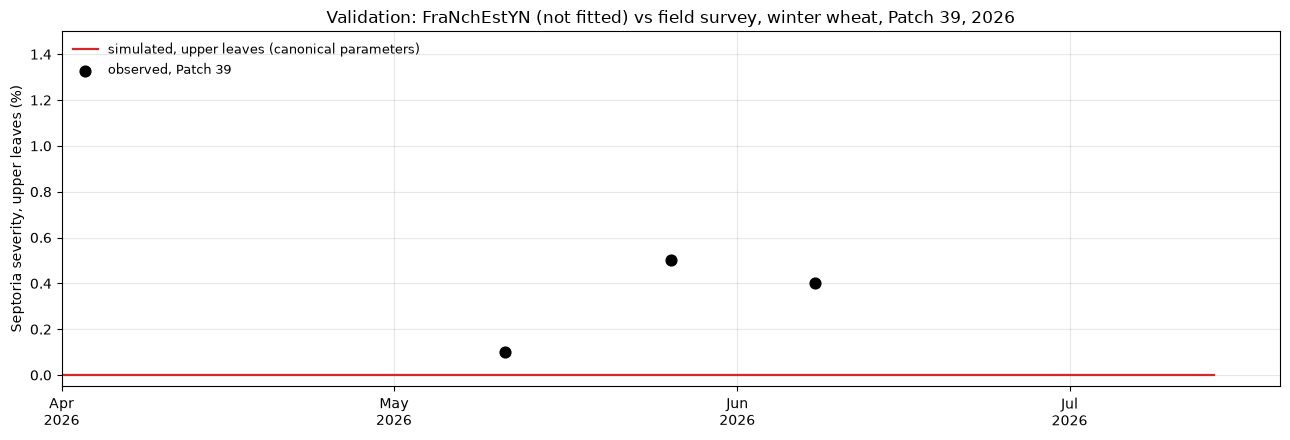

In [16]:
# --- Observed septoria severity: winter wheat, Patch 39 ---
PLOT = 'Patch 39'
obs39 = sp[(sp['crop'] == 'winter wheat') & (sp['plot_id'] == PLOT)].set_index('date')


def sim_on_survey_days(sim):
    """Simulated upper-leaf severity for each survey (the model scores a survey against the day before)."""
    return numpy.array([sim[SEVERITY_COL].get(d - pandas.Timedelta(days=1), numpy.nan) for d in obs39.index])


def rmse(sim_values):
    """Typical difference (%) between the simulation and the Patch 39 observations."""
    return float(numpy.sqrt(((obs39['bs_pct'].to_numpy() - sim_values) ** 2).mean()))


canonical_values = sim_on_survey_days(fr_sim)
validation = pandas.DataFrame({
    'BBCH': obs39['bbch_range'].to_numpy(),
    'observed (%)': obs39['bs_pct'].to_numpy(),
    'simulated (%)': canonical_values,
}, index=obs39.index.date)
display(validation.round(2))
print(f"RMSE, simulation vs {PLOT}: {rmse(canonical_values):.2f} %")

# --- Plot ---
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(fr_sim.index, fr_sim[SEVERITY_COL], color='tab:red', lw=1.6, label='simulated, upper leaves (canonical parameters)')
ax.scatter(obs39.index, obs39['bs_pct'], s=60, color='black', zorder=3, label=f'observed, {PLOT}')
ax.set_xlim(pandas.Timestamp(f'{SOW_YEAR + 1}-04-01'), pandas.Timestamp(f'{SOW_YEAR + 1}-07-20'))
ax.set_ylim(-0.05, 1.5)
ax.set_ylabel('Septoria severity, upper leaves (%)')
ax.set_title(f'Validation: FraNchEstYN (not fitted) vs field survey, winter wheat, {PLOT}, 2026')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
fig.tight_layout()
plt.show()

##### 5.2 Calibration on Patch 39

Two parameters are fitted to the three Patch 39 values:
`HydroThermalTimeOnset` (when infections may start) and `LatencyDuration`
(days until lesions show). All other parameters keep their canonical values.

**Note:** the fit is judged on the same three values it was fitted to. A good
match here shows that the model *can* be bent to these points, not that it is
right. It would need more observations to confirm.

/home/rahaman/miniforge3/envs/simpest/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HydroThermalTimeOnset: 0.57 (canonical 10, allowed 0.5–20)
LatencyDuration: 10.28 (canonical 19.5, allowed 10–25)


,BBCH,observed (%),canonical (%),fitted (%)
2026-05-11,32-37,0.1,0.0,0.00
2026-05-26,49-52,0.5,0.0,0.45
2026-06-08,71-75,0.4,0.0,0.45


RMSE: canonical 0.37 %, fitted 0.07 %
fitted run: max upper-leaf severity 0.83 %, yield loss 1.6 %


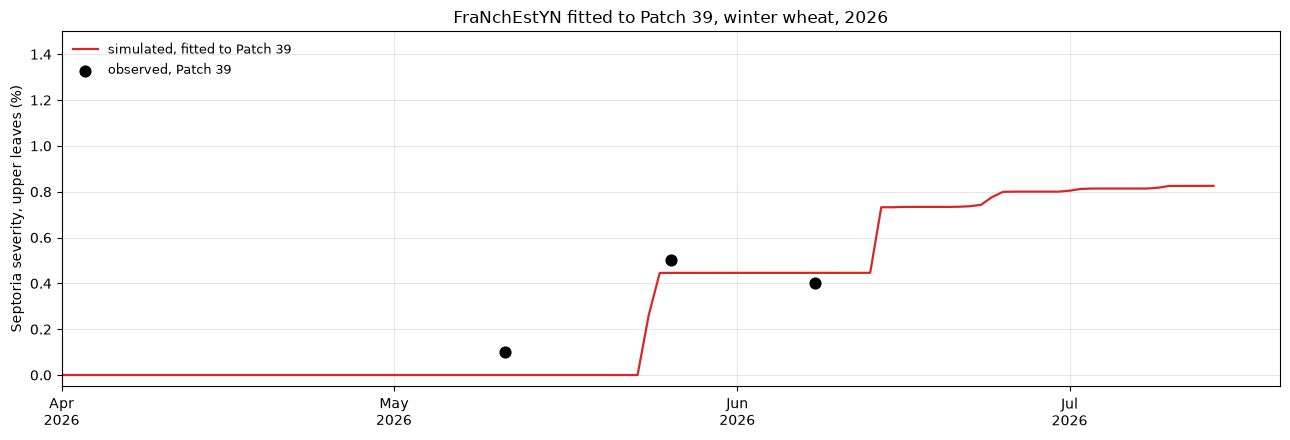

In [17]:
import contextlib
import io
from simpest.models.fr_session import FranchestynSession

CALIBRATED = ['HydroThermalTimeOnset', 'LatencyDuration']

# --- Patch 39 observations, in the table format FraNchEstYN reads ---
ref39 = pandas.DataFrame({'sName': FRANCH_SITE, 'variety': FRANCH_VARIETY, 'year': obs39.index.year,
                          'DOY': obs39.index.dayofyear, 'FINT': None,
                          FRANCH_DISEASE: obs39['bs_pct'].to_numpy()})

# --- Fit only the two parameters ---
cal_cfg = copy.deepcopy(fr_cfg)
franchestyn.deactivate_calibration(cal_cfg.disease_parameters, set(cal_cfg.disease_parameters) - set(CALIBRATED))
for p in CALIBRATED:
    cal_cfg.disease_parameters[p]['calibration'] = True
cal_cfg.is_calibration = True
cal_cfg.calibration_variable = 'disease'
cal_cfg.optimizer = 'optuna'

cal_session = FranchestynSession(cal_cfg, FRANCH_START_YEAR, FRANCH_END_YEAR, weather_df=weather_df,
                                 management_df=management_df, crop_model_df=crop_model_df, ref_df=ref39)
with contextlib.redirect_stdout(io.StringIO()):   # hide the optimizer's trial-by-trial log
    calib = cal_session.calibrate_seeds([1, 2, 3], n_trials=300)   # best of three starts; values go into cal_cfg
    cal_result = cal_session.run_forward()
cal_sim = fr_diagnostics.simulation_frame(cal_result).set_index('Date')   # severity in %
calibrated_values = sim_on_survey_days(cal_sim)

# --- Fitted values ---
for p in CALIBRATED:
    print(f"{p}: {cal_cfg.disease_parameters[p]['value']:.2f} (canonical {fr_cfg.disease_parameters[p]['value']:g}, "
          f"allowed {cal_cfg.disease_parameters[p]['min']:g}–{cal_cfg.disease_parameters[p]['max']:g})")

# --- Observed vs simulated ---
comparison = validation.rename(columns={'simulated (%)': 'canonical (%)'})
comparison['fitted (%)'] = calibrated_values
display(comparison.round(2))
print(f"RMSE: canonical {rmse(canonical_values):.2f} %, fitted {rmse(calibrated_values):.2f} %")

cal_end = cal_sim.iloc[-1]
print(f"fitted run: max upper-leaf severity {cal_sim[SEVERITY_COL].max():.2f} %, "
      f"yield loss {100 * (1 - cal_end['YieldActual'] / cal_end['YieldAttainable']):.1f} %")

# --- Plot ---
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(cal_sim.index, cal_sim[SEVERITY_COL], color='tab:red', lw=1.6, label=f'simulated, fitted to {PLOT}')
ax.scatter(obs39.index, obs39['bs_pct'], s=60, color='black', zorder=3, label=f'observed, {PLOT}')
ax.set_xlim(pandas.Timestamp(f'{SOW_YEAR + 1}-04-01'), pandas.Timestamp(f'{SOW_YEAR + 1}-07-20'))
ax.set_ylim(-0.05, 1.5)
ax.set_ylabel('Septoria severity, upper leaves (%)')
ax.set_title(f'FraNchEstYN fitted to {PLOT}, winter wheat, 2026')
ax.grid(alpha=0.3)
ax.legend(loc='upper left', frameon=False, fontsize=9)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
fig.tight_layout()
plt.show()

##### 5.3 What the results say

- **The model gets the season right.** Without any fitting it predicts almost
  no septoria, and Patch 39 had almost none (0.1–0.5 % leaf area). The reason
  is the weather: spring 2026 was dry (April: mean humidity 63 %, under 3 wet
  hours a day), and septoria needs long wet periods.
- **The error is small.** The not-fitted model is 0.37 % off on average. The
  survey itself reads in steps of 0.1 %.
- **The fit matches Patch 39** (error 0.37 → 0.07 %), but with care: two
  parameters were fitted to three values, and both end at the edge of their
  allowed range (`HydroThermalTimeOnset` 0.57 of 0.5–20, `LatencyDuration`
  10.3 of 10–25). The fitted values describe Patch 39 in 2026. They are not
  confirmed by other data, so the 1.6 % yield loss is only indicative.
- **11 May is still missed.** Even the fitted model shows no disease that
  early. In the field, the first infections were probably earlier than the
  model allows.
- **What this test cannot show.** One season with almost no disease cannot
  tell whether the model would get a real epidemic right (timing, speed,
  yield loss).
- **Open points from the field.** The variety and any fungicide sprays are not
  in the inputs (`Generic`, fully susceptible, no fungicide). The crop is
  simulated without water shortage, and no yield was measured, so the yield
  level is not checked.